# Détection d'une figure : du simulateur à l'entraînement
Dataset synthétique → redimensionnement → apprentissage → feature maps → prédiction + NMS.

In [4]:
import os, random
import numpy as np
import torch
from PIL import Image
from torch.utils.data import DataLoader, TensorDataset

os.chdir(os.path.dirname(os.path.abspath("")) if os.path.basename(os.path.abspath("")) == "notebooks" else ".")

from src.dataset_generator import make_example
from src.detector import Detector, STRIDE, predict
from src.visualize import show_images, show_feature_maps, show_detections
from src.detector import code
from src.train import evaluate, train

MODEL_SIZE = 64          # taille d'entrée utilisée à l'entraînement
assert MODEL_SIZE % STRIDE == 0   # la grille de feature maps fait MODEL_SIZE // STRIDE

## 1. Génération du dataset
On génère volontairement des images d'une taille différente de celle du modèle.

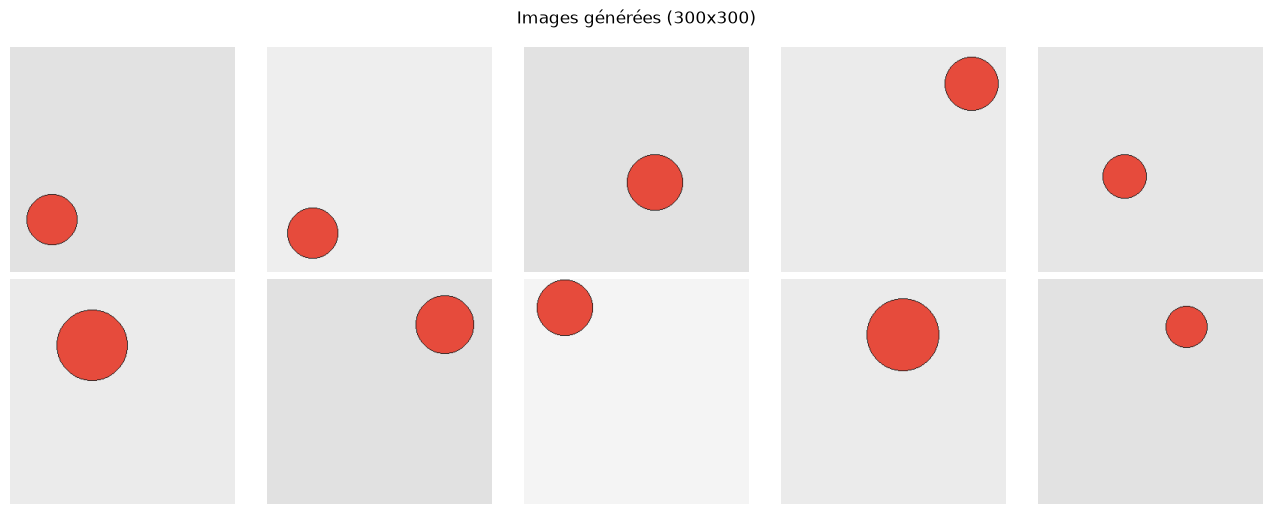

In [5]:
RAW_SIZE = 300
rng = random.Random(123)
raw = [make_example(RAW_SIZE, "circle", rng)[0] for _ in range(10)]
show_images(raw, f"Images générées ({RAW_SIZE}x{RAW_SIZE})")

## 2. Adaptation de la taille d'entrée
Le détecteur attend `MODEL_SIZE`×`MODEL_SIZE` (multiple du stride) : on redimensionne puis on convertit en tenseurs.

In [6]:
def to_input(image):
    image = image.convert("RGB").resize((MODEL_SIZE, MODEL_SIZE), Image.BILINEAR)
    return torch.from_numpy(np.asarray(image, dtype=np.float32).copy()).permute(2, 0, 1) / 255.0

images = torch.stack([to_input(im) for im in raw])
print(images.shape)

torch.Size([10, 3, 64, 64])


## 3. Génération d'un jeu de données d'entraînement plus grand
On génère 2 000 images pour l'entraînement et 400 images indépendantes pour la validation. Les boîtes sont redimensionnées comme les images avant l'encodage des cibles.

In [7]:

def make_dataset(count, seed):
    rng = random.Random(seed)
    scale = MODEL_SIZE / RAW_SIZE
    dataset_images, targets = [], []
    for _ in range(count):
        image, label = make_example(RAW_SIZE, "circle", rng)
        cx, cy, width, height = (float(value) * scale for value in label.split())
        dataset_images.append(to_input(image))
        targets.append(code(cx, cy, width, height, size=MODEL_SIZE))
    return TensorDataset(torch.stack(dataset_images), torch.stack(targets))



In [8]:
TRAIN_SAMPLES = 2_00
VAL_SAMPLES = 40
BATCH_SIZE = 64
EPOCHS = 5

torch.manual_seed(0)
train_set = make_dataset(TRAIN_SAMPLES, seed=7)
val_set = make_dataset(VAL_SAMPLES, seed=8)
train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_set, batch_size=BATCH_SIZE)

model = Detector()
optimizer = torch.optim.Adam(model.parameters(), lr=3e-3)
for epoch in range(1, EPOCHS + 1):
    mean_loss = train(model, train_loader, optimizer)
    val_iou, val_accuracy = evaluate(model, val_loader, MODEL_SIZE)
    print(f"epoch {epoch:2d}  loss {mean_loss:.4f}  "
          f"val IoU {val_iou:.3f}  IoU>0.5 {val_accuracy:.0%}")

model.eval();

epoch  1  loss 0.0285  val IoU 0.235  IoU>0.5 0%
epoch  2  loss 0.0205  val IoU 0.243  IoU>0.5 0%
epoch  3  loss 0.0171  val IoU 0.250  IoU>0.5 0%
epoch  4  loss 0.0153  val IoU 0.268  IoU>0.5 0%
epoch  5  loss 0.0138  val IoU 0.291  IoU>0.5 8%


## 4. Feature maps

torch.Size([10, 32, 8, 8])


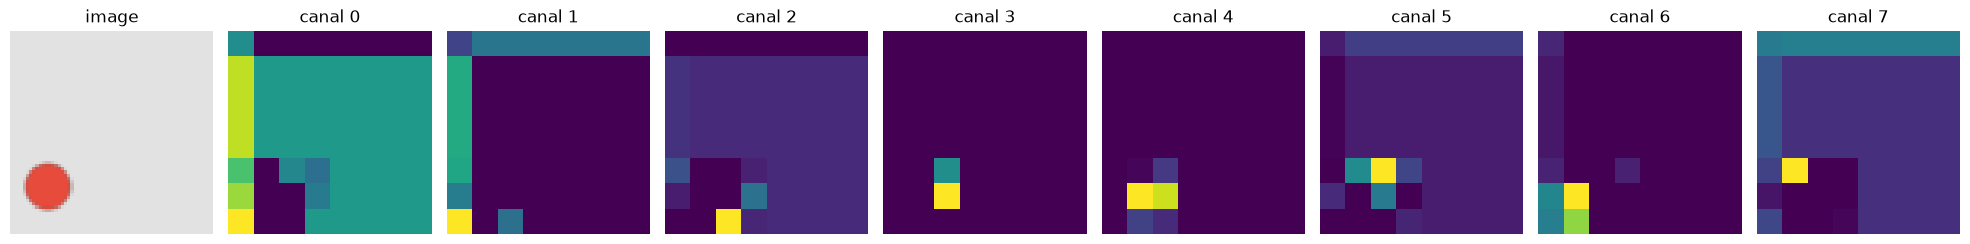

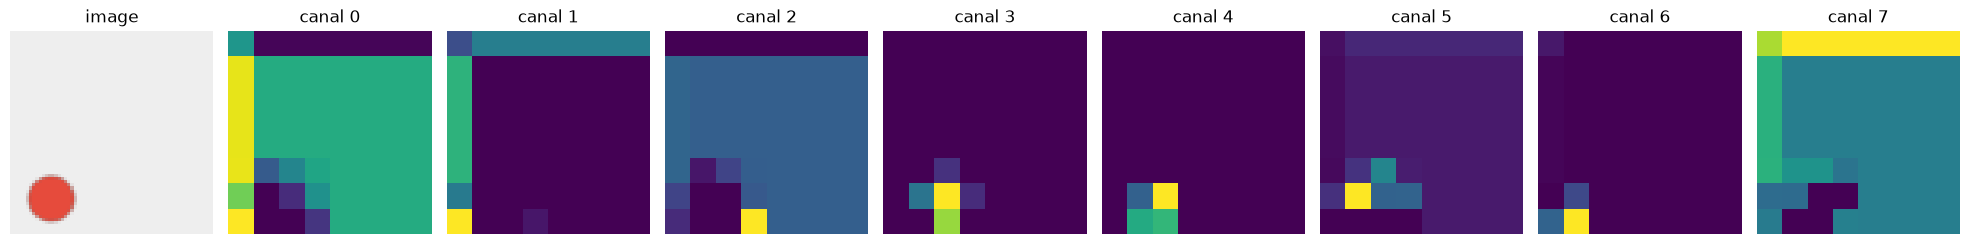

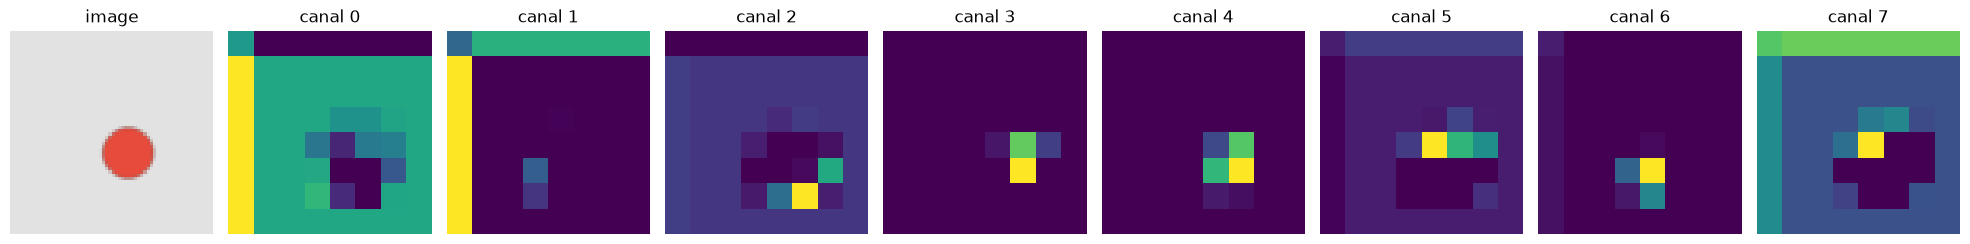

tensor([[ 0.1880,  0.1635, -0.1725],
        [ 0.0503, -0.0150, -0.0287],
        [-0.0720,  0.0779, -0.1203]], grad_fn=<SelectBackward0>)


In [9]:
with torch.no_grad():
    maps = model.feature_maps(images)   # (N, 32, 8, 8)
print(maps.shape)
for i in range(3):
    show_feature_maps(images[i], maps[i], n_maps=8)
    
print(model.backbone[0].weight[3, 0, :, :])

## 5. Prédiction, décodage et NMS : une boîte par image

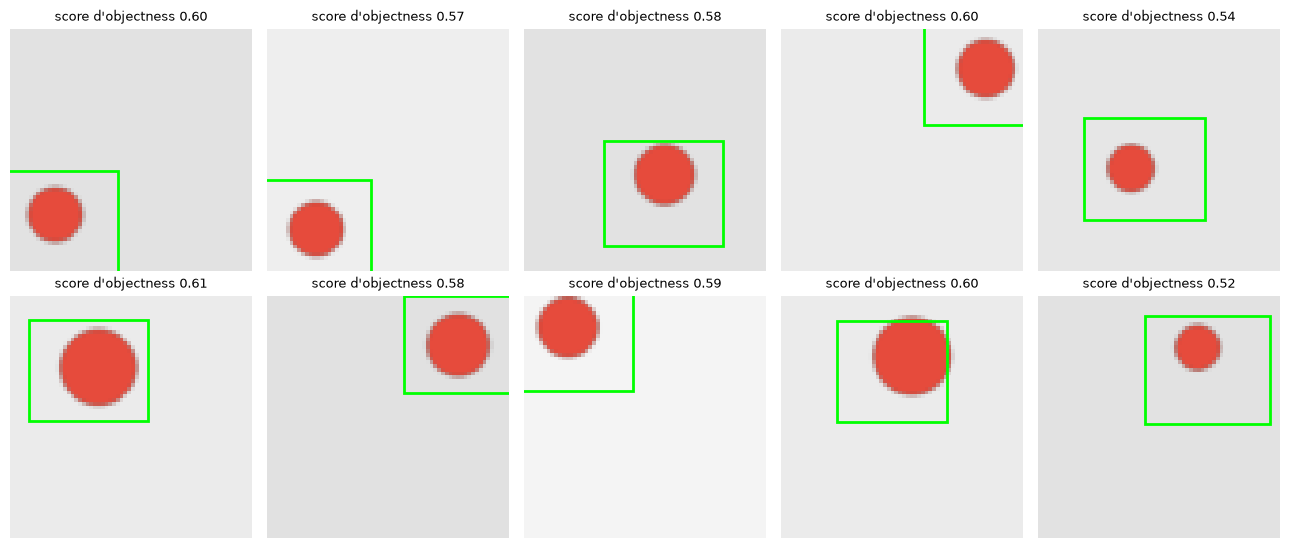

In [10]:
with torch.no_grad():
    logits = model(images)
results = [predict(l, MODEL_SIZE) for l in logits]
show_detections(list(images), [b for b, _ in results], [s for _, s in results])